# Week 10: Visualization (part 2) + GIS data
## Name: Bria Pickel-Fridman
## 11/2/2026

In [1]:

# first we need to import our visualization libraries and any other related components

import json # need to parse geojson
import re # needed for wordcloud example

import matplotlib.pyplot as plt # 
import pandas as pd # using data frames with our plotly visualization
import plotly.express as px # px shorthand is used in plotly examples
import pydeck as pdk # pdk is used as a shorthand for pydeck examples

from IPython.display import HTML, IFrame # needed to display pydeck visualization in the notebook
from wordcloud import STOPWORDS, wordcloud #


## Visualizing as poll data

I have included two files (`house_average_recent.csv` and `senate_average_recent.csv`) which contain average polls for seante and house races for the 2026 US election. Firt we want to load these as a dataframe:

In [2]:
house = pd.read_csv("house_average_recent.csv")
senate = pd.read_csv("senate_average_recent.csv")

In [3]:

#preview what's in each file:
house.head()

,id,state,district,dem,rep,margin,polls,latest,days_old
0,AK-1,AK,1,5.8,45.8,-40.1,1,2026-10-30,1
1,AL-2,AL,2,45.0,49.5,-4.5,1,2026-10-25,6
2,AR-2,AR,2,48.0,52.0,-4.0,1,2026-10-14,17
3,AZ-1,AZ,1,49.4,45.0,4.4,1,2026-10-28,3
4,AZ-2,AZ,2,50.0,48.0,2.0,1,2026-10-14,17


In [4]:
senate.head()

,state,dem,rep,margin,polls,latest,days_old
0,AK,48.7,47.1,1.6,2,2026-10-30,2
1,AL,39.5,47.8,-8.3,1,2026-10-24,8
2,AR,39.0,55.0,-16.0,1,2026-10-28,4
3,FL,43.6,49.3,-5.7,7,2026-10-30,2
4,GA,53.9,43.8,10.1,3,2026-10-23,9


Since our data doesn't cleanly add up to 100% for each senate/house poll average, we need to calculate a 3rd value for "other" to make up for the missing points!

other = 100 - dem - rep

In [5]:
senate["other"]=(100-senate["dem"]-senate["rep"]).clip(lower=0).round(1)

In [6]:
senate.head()

,state,dem,rep,margin,polls,latest,days_old,other
0,AK,48.7,47.1,1.6,2,2026-10-30,2,4.2
1,AL,39.5,47.8,-8.3,1,2026-10-24,8,12.7
2,AR,39.0,55.0,-16.0,1,2026-10-28,4,6.0
3,FL,43.6,49.3,-5.7,7,2026-10-30,2,7.1
4,GA,53.9,43.8,10.1,3,2026-10-23,9,2.3


In [7]:
# a dictionary of the names we want in the legend: {old column name: new name}
party_names = {"dem": "Democrat", "other": "Other / undecided", "rep": "Republican"}

# the color of each bar segment, by its new name 
colors = {"Democrat": "blue", "Other / undecided": "grey", "Republican": "red"}

# sort the states from the smallest margin (most Republican) to the largest (most Democratic),
# and rename the columns using the dictionary above
senate_sorted = senate.sort_values("margin").rename(columns=party_names)

senate_sorted.head()

,state,Democrat,Republican,margin,polls,latest,days_old,Other / undecided
6,ID,13.0,43.0,-30.0,1,2026-07-30,94,44.0
25,SD,18.0,43.0,-25.0,1,2026-05-30,155,39.0
22,OK,26.0,48.5,-22.5,1,2026-08-06,87,25.5
26,TN,32.0,54.5,-22.5,1,2026-08-26,67,13.5
16,MT,17.4,37.9,-20.5,3,2026-10-23,9,44.7


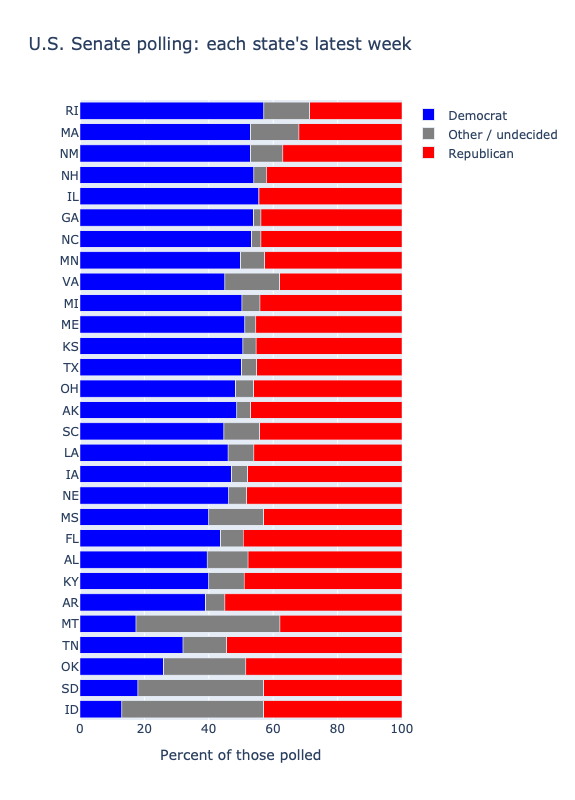

In [8]:
# bar graph method in plotly library
fig = px.bar(
    senate_sorted,
    x=["Democrat", "Other / undecided", "Republican"],   # a list of columns: each one becomes a segment, stacked left to right
    y="state",                                           # one bar for each state
    orientation="h",                                     # "h" for horizontal bars
    color_discrete_map=colors,                           # which color goes with which segment
    labels={"value": "Percent", "state": "State"},       # px calls the length of each segment "value" in the hover box
    hover_data={"polls": True, "latest": True},          # also show the number of polls and the latest poll date
    height=800,                                          # tall enough for 29 bars
    title="U.S. Senate polling: each state's latest week",
)

fig.update_layout(
    legend_title_text="",                  # remove the legend's default title
    xaxis_title="Percent of those polled",
    xaxis_range=[0, 100],                  # always show the full 0 to 100 percent
    yaxis_title="",
    yaxis={"dtick": 1},                    # label every bar (otherwise Plotly may label every other one)
)

fig.show()

## plotting the data on a map!

We can generate a geographic map using our dats, combining it with region shapes (states, congressional districts, etc)
Plotly contains US state outlines by default so we don't need to add them

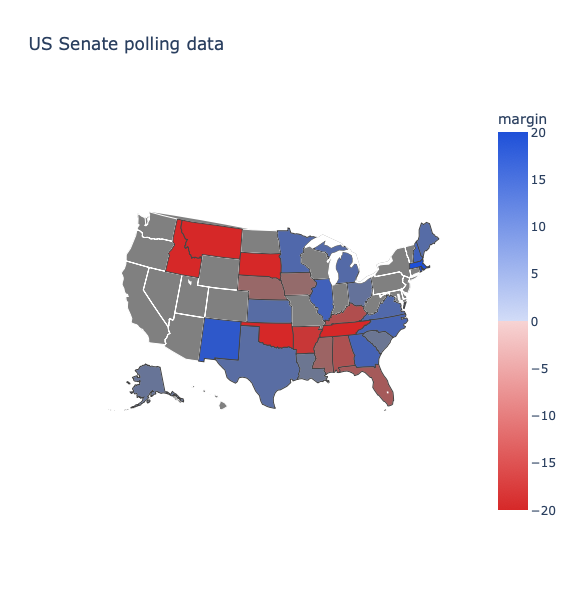

In [9]:
red = "214,40,40" # this is the RGB representation of red
blue = "30, 80, 216" #RGB representation of blue

# we can define a color scale by which our data will be represented

color_scale = [
    [0.0, f"rgba({red}, 1)"],      # Republican lead of 20+ points: solid red (alpha 1 means fully opaque)
    [0.5, f"rgba({red}, 0.2)"],    # tied: faint (alpha 0.2 means mostly see-through)
    [0.5, f"rgba({blue}, 0.2)"],   # ...and the same position again, so that the color switches from red to blue at a tie
    [1.0, f"rgba({blue}, 1)"],     # Democratic lead of 20+ points: solid blue
]


colorbar = {
    "title": "Lead by margin",
    "tickvals": [-20, -10, 0, 10, 20],
    "ticktext": ["R+20", "R+10", "Tie" "D+10" "D+20"]
}

fig = px.choropleth(
    senate,
    locations="state", # this tells the ployly library which column of our data contains location information
    locationmode = "USA-states", # this tells plotly that we are dealing with US state data and to plot accordingly
    scope="usa", #zooms in on the US
    color="margin", # give color to each region based on "Margin" column of dataset
    color_continuous_scale = color_scale, # references the color scale we made in the beginning of the block
    range_color=[-20,20],
    height=600,
    title="US Senate polling data"
)

fig.update_geos(landcolor="grey")

fig.show()

Word clouds
A word cloud draws words at sizes that show how often they appear. The wordcloud library turns a text, or a table of word counts, into an image. We'll use a whole book: How the Other Half Lives: Studies Among the Tenements of New York (1890), by Jacob A. Riis, a journalist and photographer who documented life in the city's tenements. The text comes from 

## Word clouds
A word cloud draws words at sizes that show how often they appear. The wordcloud library turns a text, or a table of word counts, into an image. We'll use a whole book: How the Other Half Lives: Studies Among the Tenements of New York (1890), by Jacob A. Riis, a journalist and photographer who documented life in the city's tenements. The text comes from 

In [11]:
# read the whole book into one string, the same way we read other text files
# (encoding="utf-8" makes sure that special characters are read correctly)
with open("mee_exercisesinknitting.txt", "r", encoding="utf-8") as file:
    book = file.read()

# Project Gutenberg adds a license and some information before and after the book. Each is separated from the
# book by a line starting with "*** START OF" or "*** END OF". .index() gives the position of that text in the string
start = book.index("*** START OF")
end = book.index("*** END OF")

# move the start to the end of the "START" line: the next newline ("\n") after it
start = book.index("\n", start)

# slice the string to keep only what is between the two markers
text = book[start:end]

print(len(book), "characters in the file,", len(text), "in the actual text")

113692 characters in the file, 94357 in the actual text


### 1. Get the Text

WordCloud wants one long string, and text is already one. Let's check the beginning and the end. We kept the whole book, and the end has a few notes from the people who prepared this edition, which are small enough to leave in.

In [12]:
# text[:300] is the first 300 characters, and text[-300:] is the last 300
print(text[:300])
print("...")
print(text[-300:])

# .split() cuts a string into words wherever there is a space or a line break, so len() of the result is a word count
print(len(text.split()), "words")






Produced by Andrew Sly, Mark C. Orton and the Online
Distributed Proofreading Team at http://www.pgdp.net







EXERCISES IN KNITTING.

BY

CORNELIA MEE,

AUTHORESS OF A MANUAL OF KNITTING, NETTING, AND CROCHET WORK;
THE COMPANION TO THE WORK TABLE; CROCHET EXPLAINED AND
ILLUSTRATED; CROCHET D
...
row:--Knit 2 together, knit 11, knit 2 together, and
repeat.

Fourth row:--Seam 2 together, seam 9, seam 2 together, and
repeat.

Fifth row:--Knit 2 together, knit 7, knit 2 together.

Sixth row:--Seamed.

Seventh row:--Same as 1st.



FINIS.

PRINTED BY WOOD BROTHERS PARSONAGE LANE, BATH.










17141 words


## 2. A first word cloud
generate() counts the words and lays them out. plt.imshow() displays the image, and plt.axis("off") hides the plot's axes. random_state makes the layout the same every time.

In [13]:
# make the cloud: the size of the image in pixels, a white background, and a fixed random_state
# (the layout uses random choices, and a fixed number makes them the same every time)
cloud = WordCloud(width=900, height=500, background_color="white", random_state=1).generate(text)

plt.figure(figsize=(10, 6))                  # the size of the plot, in inches
plt.imshow(cloud, interpolation="bilinear")  # draw the cloud's image (bilinear smooths it)
plt.axis("off")                              # hide the plot's axes
plt.show()

NameError: name 'WordCloud' is not defined

WordCloud already leaves out common English words such as "of" and "the" (its stop words), but the result is still full of ordinary words like "one", "upon", and "will". Notice, too, that it counts some pairs of words together, like "New York".

### 3. Choose the words to leave out
STOPWORDS is a set of words. We can add our own with | (the union of two sets) and pass the result to WordCloud.

In [14]:
# STOPWORDS is a set, and | joins two sets together: the built-in stop words, plus a set of our own.
# Look at the first cloud, and add the words that are common but don't tell us much about this book
my_stopwords = STOPWORDS | {
    "one", "two", "three", "four", "five", "six", "upon", "will", "may", "even", "every", "many", "made", "make",
    "much", "must", "way", "now", "yet", "still", "little", "see", "seen", "come", "came", "day", "year", "years",
    "chapter", "illustration",           # headings and captions in the book, not part of its text
}

cloud = WordCloud(
    width=900,
    height=500,
    background_color="white",
    stopwords=my_stopwords,      # the words to leave out
    colormap="viridis",          # the color palette: try "plasma", "Set2", "Blues"
    max_words=80,                # only draw the 80 most common words
    random_state=1,
).generate(text)

plt.figure(figsize=(10, 6))
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.show()

NameError: name 'WordCloud' is not defined

### 4. A cloud from counts
We don't have to start from text. If we already have counts, like the output of value_counts(), generate_from_frequencies() draws a cloud from a dictionary of {word: count}. That gives us full control over what gets counted. Here, we'll use a regular expression from Part 9 to pull out the words, count them with pandas, and drop the stop words ourselves.

In [15]:
# re.findall() returns every match of a pattern. [a-z']+ means "one or more lowercase letters or apostrophes",
# so each match is a word. We lowercase the text first, so that "The" and "the" are counted together
words = re.findall(r"[a-z']+", text.lower())

# a list of words becomes a pandas Series, and .value_counts() counts each one, with the most common first
counts = pd.Series(words).value_counts()

# .isin() is True for the words that are in our set of stop words. The ~ flips it, so we keep the other words
counts = counts[~counts.index.isin(my_stopwords)]

# the 100 most common words, as a dictionary like {"tenement": 317, "street": 157, ...}
word_counts = counts.head(100).to_dict()

# a dictionary's .items() are its (key, value) pairs. We make a list of them and look at the first five
print(list(word_counts.items())[:5])

# this time we make the WordCloud first, and then give it the counts with a second call
cloud = WordCloud(width=900, height=500, background_color="white", colormap="copper", random_state=1)
cloud = cloud.generate_from_frequencies(word_counts)

plt.figure(figsize=(10, 6))
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.show()

[('knit', 1579), ('row', 531), ('together', 522), ('stitches', 344), ('seam', 305)]


NameError: name 'WordCloud' is not defined

Save a cloud as an image file with to_file():

In [16]:
# save the most recent cloud as a PNG image, in this folder
cloud.to_file("riis_cloud.png")

NameError: name 'cloud' is not defined

Things to try
Change max_words, colormap, or the size of the image, and rerun.
In the first clouds, WordCloud counted pairs like "New York". Add collocations=False to WordCloud(...) to count single words only. What changes?
Make a cloud from a different text: another book from Project Gutenberg (choose "Plain Text UTF-8")
Hide »
Versions
Flask 3.1.3
Time
CPU: 1097.34ms (1464.86ms)
HTTP Headers
Request Vars
Config
Templates
0 rendered
SQLAlchemy
Unavailable
Logging
3 messages
Route List
12 routes
Profiler
in-active
Flamegraph
in-active

### Homework

In [22]:
native = pd.read_csv("all_nativeamerican_artworks.csv")
native_with_state = pd.read_csv("nativeamerican_artworks_withstate.csv")

#preview what's in each file:
native.head()

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,department,...,classification,rightsAndReproduction,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber
0,120950,False,1976.55,1976.0,True,https://images.metmuseum.org/CRDImages/ao/orig...,https://images.metmuseum.org/CRDImages/ao/web-...,[],NaN,The Michael C. Rockefeller Wing,...,Feathers-Costumes,NaN,NaN,2026-10-21T04:58:17.613Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
1,27229,False,1978.132.2,1978.0,False,NaN,NaN,[],NaN,Arms and Armor,...,Shafted Weapons,NaN,NaN,2025-03-06T04:54:30Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
2,500882,False,89.4.3560,1889.0,False,NaN,NaN,[],NaN,Musical Instruments,...,Aerophone-Blow Hole-side-blown flute (transverse),NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
3,500888,False,06.1257,1906.0,False,NaN,NaN,[],NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
4,500889,False,06.1258,1906.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q116412906,False,NaN


In [21]:
native_with_state.head()

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,department,...,classification,rightsAndReproduction,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber
0,500888,False,06.1257,1906.0,False,NaN,NaN,[],NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
1,500889,False,06.1258,1906.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,https://www.wikidata.org/wiki/Q116412906,False,NaN
2,501178,False,"89.4.562a, b",1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,"[{'constituentID': 155406, 'role': 'Maker', 'n...",Musical Instruments,...,Membranophone-single-headed / frame drum,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
3,501180,False,89.4.564,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Chordophone-Lute,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
4,501189,False,89.4.573,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Aerophone-Blow Hole-end-blown flute (vertical),NaN,NaN,2024-05-17T04:51:53.097Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN


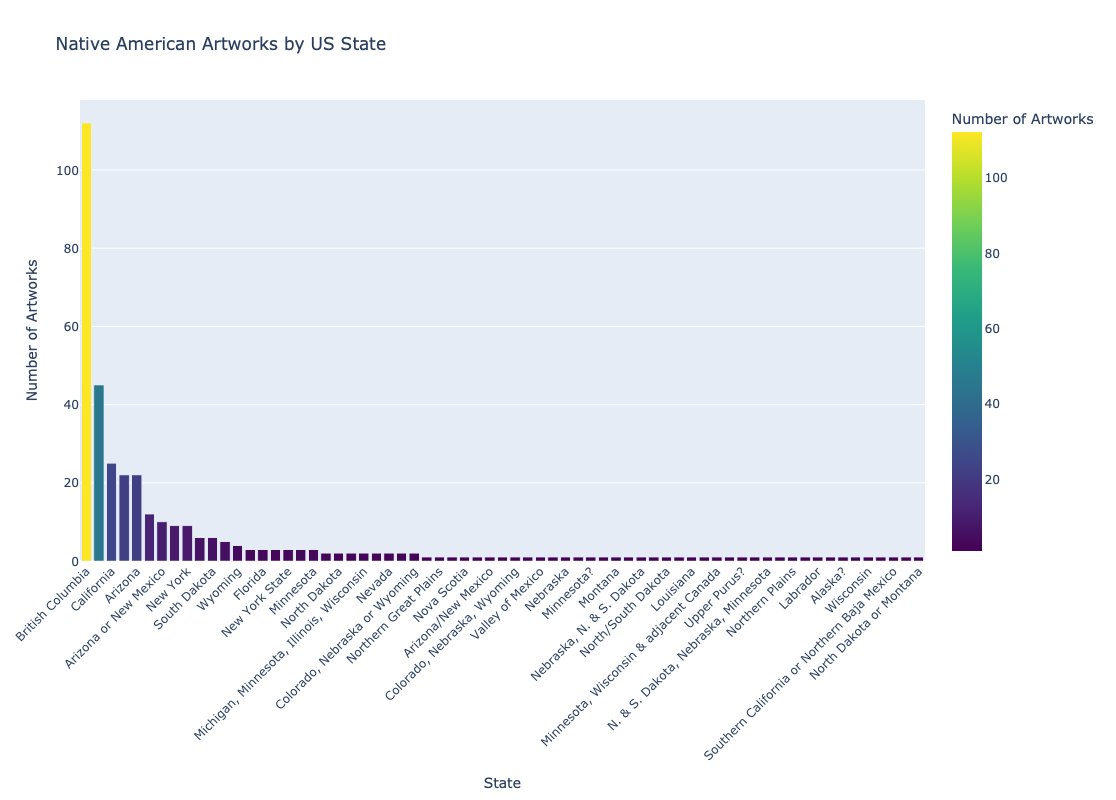

In [32]:
state_counts = native_with_state["state"].value_counts().reset_index()

state_counts.columns = ["state", "artwork_count"]

# Create bar graph
fig = px.bar(
    state_counts,
    x="state",
    y="artwork_count",
    title="Native American Artworks by US State",
    labels={
        "state": "State",
        "artwork_count": "Number of Artworks"
    },
    color="artwork_count",
    height=800,
    color_continuous_scale="Viridis"
)

fig.update_layout(
    xaxis_title="State",
    yaxis_title="Number of Artworks",
    xaxis_tickangle=-45,
    xaxis={"categoryorder": "total descending"}
)

fig.show()

This exercise has made me realize just how messy the state data entries are, and how much cleaning I would have to do in order to make a map work. Is is appropriate to make assumptions and change the data structure to fit? Foe example if the entry is "Nebraska, N & S. Dakota" is it safe to assume they mean the artwork originated in Nebraska, North Dakota, or South Dakota?

there are a number of entries that will work as entered. I just need to filter for entries containing "and", "or", "/" ","

I chose to keep entries with "?" because I did not want to totally erase all uncertainty from the results. It is very clear that var

In [29]:
native_with_state_filtered = pd.read_csv("nativeamerican_artworks_withstate_filtered.csv")

#preview what's in each file:
native_with_state_filtered.head()

,objectID,isHighlight,accessionNumber,accessionYear,isPublicDomain,primaryImage,primaryImageSmall,additionalImages,constituents,department,...,classification,rightsAndReproduction,linkResource,metadataDate,repository,objectURL,tags,objectWikidata_URL,isTimelineWork,GalleryNumber
0,501180,False,89.4.564,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Chordophone-Lute,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
1,501194,False,89.4.578,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Aerophone-Blow Hole-side-blown flute (transverse),NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
2,501197,False,89.4.581,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Idiophone-Shaken-rattle,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
3,501200,False,89.4.584,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Idiophone-Struck-bell-clapper,NaN,NaN,2024-03-22T04:53:07.663Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN
4,501203,False,89.4.587,1889.0,True,https://images.metmuseum.org/CRDImages/mi/orig...,https://images.metmuseum.org/CRDImages/mi/web-...,['https://images.metmuseum.org/CRDImages/mi/or...,NaN,Musical Instruments,...,Membranophone-single-headed / frame drum,NaN,NaN,2025-01-31T04:54:36.6Z,"Metropolitan Museum of Art, New York, NY",https://www.metmuseum.org/art/collection/searc...,NaN,NaN,False,NaN


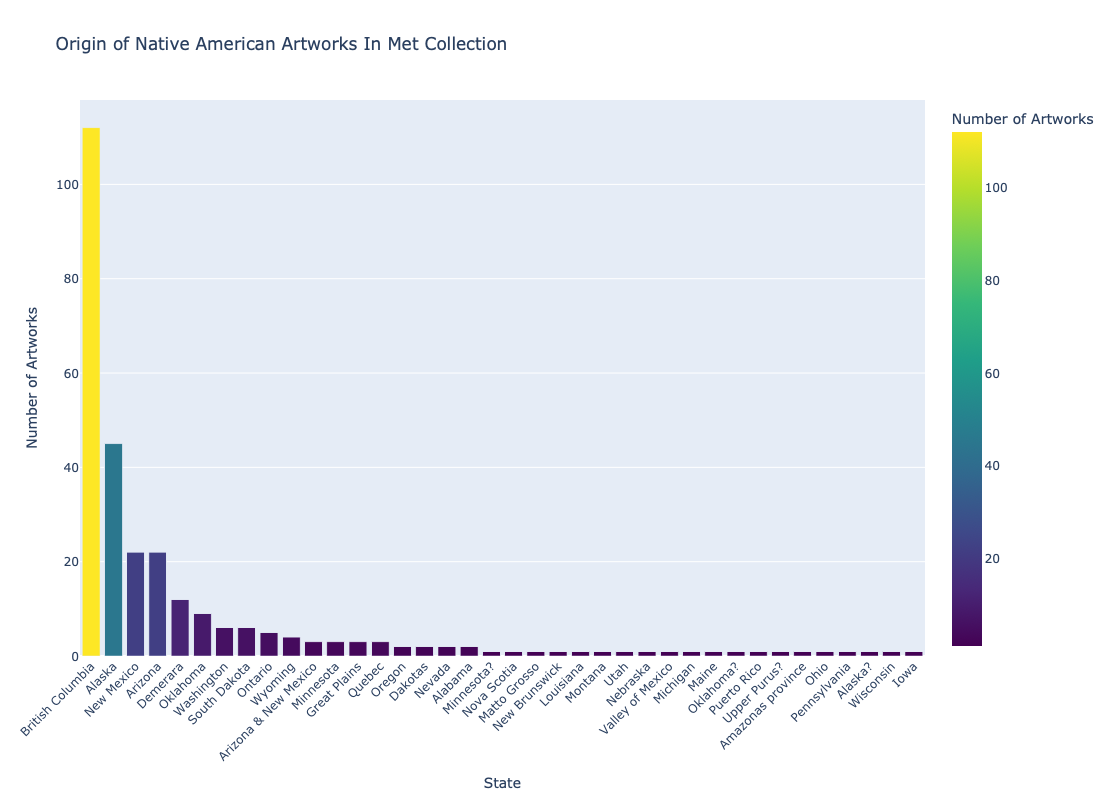

In [33]:
state_counts = native_with_state_filtered["state"].value_counts().reset_index()

state_counts.columns = ["state", "artwork_count"]

# Create bar graph
fig = px.bar(
    state_counts,
    x="state",
    y="artwork_count",
    title="Origin of Native American Artworks In Met Collection",
    labels={
        "state": "State",
        "artwork_count": "Number of Artworks"
    },
    color="artwork_count",
    height=800,
    color_continuous_scale="Viridis"
)

fig.update_layout(
    xaxis_title="State",
    yaxis_title="Number of Artworks",
    xaxis_tickangle=-45,
    xaxis={"categoryorder": "total descending"}
)

fig.show()